Aqui voy a empezar a colocar lo que necesitamos para empezar.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

#Esta es la semilla que utilizamos para el deep learning 
SEMILLA = 42
np.random.seed(SEMILLA)

#Funcion para el dataset 

def resumen(df):
    # Ficha técnica por columna: tipo, nulos, cardinalidad y un ejemplo
    return pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "no_nulos": df.notna().sum(),
        "nulos": df.isna().sum(),
        "%_nulos": (df.isna().mean() * 100).round(2),
        "valores_unicos": df.nunique(),
        "ejemplo": df.iloc[0],
    })

In [4]:
RUTA_DATOS = "dataset/Dataset_Mod.csv"
df = pd.read_csv(RUTA_DATOS, sep=";")
print("Dimensiones:", df.shape)
display(df.head())
display(resumen(df))

Dimensiones: (60, 14)


,"Week of the month (first week, second, third, fourth or fifth week",Day of the week (Monday to Friday),Non-urgent order,Urgent order,Order type A,Order type B,Order type C,Fiscal sector orders,Orders from the traffic controller sector,Banking orders (1),Banking orders (2),Banking orders (3),Target (Total orders),Unnamed: 13
0,1,4,316.307,223.270,61.543,175.586,302.448,0.000,65.556,44.914,188.411,14.793,539.577,NaN
1,1,5,128.633,96.042,38.058,56.037,130.580,0.000,40.419,21.399,89.461,7.679,224.675,NaN
2,1,6,43.651,84.375,21.826,25.125,82.461,1.386,11.992,3.452,21.305,14.947,129.412,NaN
3,2,2,171.297,127.667,41.542,113.294,162.284,18.156,49.971,33.703,69.054,18.423,317.120,NaN
4,2,3,90.532,113.526,37.679,56.618,116.220,6.459,48.534,19.646,16.411,20.257,210.517,NaN


,tipo,no_nulos,nulos,%_nulos,valores_unicos,ejemplo
"Week of the month (first week, second, third, fourth or fifth week",int64,60,0,0.0,5,1.000
Day of the week (Monday to Friday),int64,60,0,0.0,5,4.000
Non-urgent order,float64,60,0,0.0,60,316.307
Urgent order,float64,60,0,0.0,60,223.270
Order type A,float64,60,0,0.0,60,61.543
Order type B,float64,60,0,0.0,60,175.586
Order type C,float64,60,0,0.0,60,302.448
Fiscal sector orders,float64,60,0,0.0,48,0.000
Orders from the traffic controller sector,float64,60,0,0.0,60,65.556
Banking orders (1),float64,60,0,0.0,60,44.914


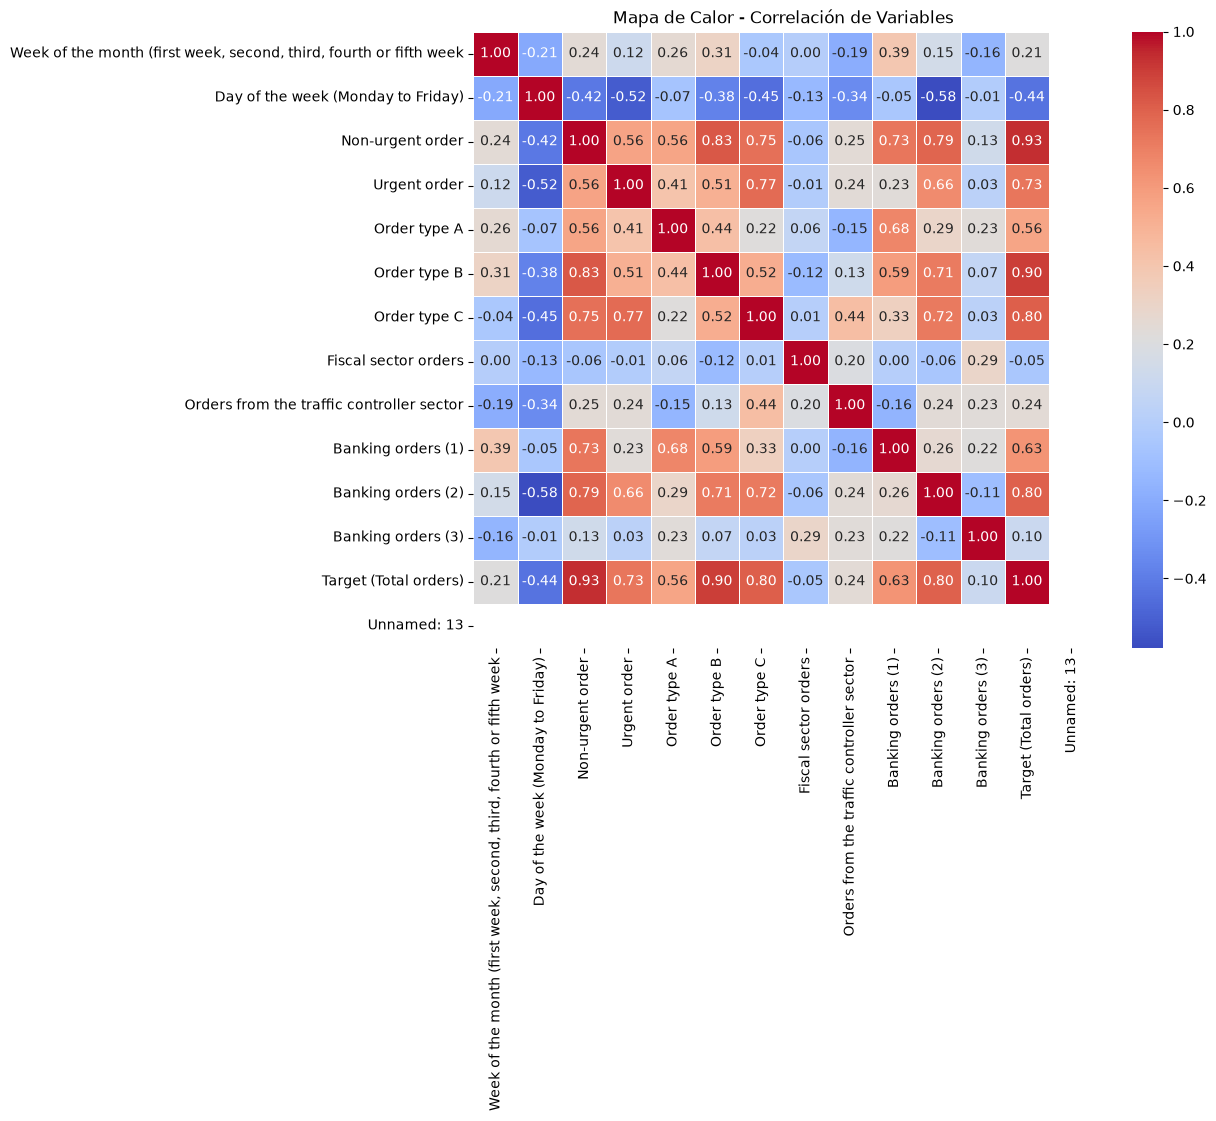

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# Suponiendo que tu DataFrame se llama df y la columna objetivo es 'Target (Total orders)'
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Mapa de Calor - Correlación de Variables")
plt.show()

Non-urgent order                                                      0.934518
Order type B                                                          0.900673
Order type C                                                          0.804984
Banking orders (2)                                                    0.798447
Urgent order                                                          0.729785
Banking orders (1)                                                    0.630365
Order type A                                                          0.559735
Orders from the traffic controller sector                             0.244712
Week of the month (first week, second, third, fourth or fifth week    0.211709
Banking orders (3)                                                    0.100901
Fiscal sector orders                                                 -0.052116
Day of the week (Monday to Friday)                                   -0.435286
Unnamed: 13                                         

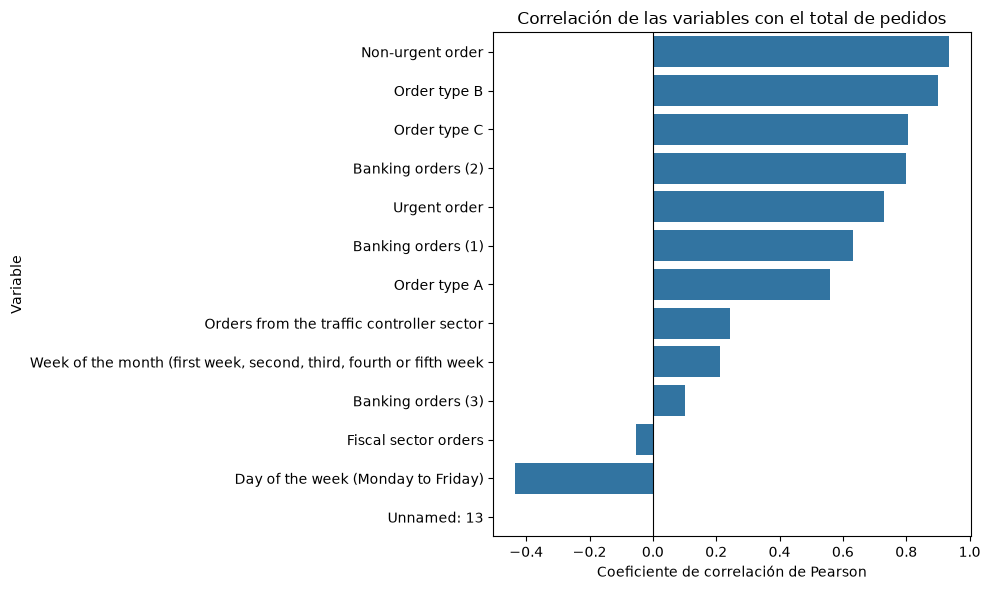

In [24]:
target = "Target (Total orders)"

correlaciones = (
    df.corr(numeric_only=True)[target]
    .drop(target)
    .sort_values(ascending=False)
)

display(correlaciones)

plt.figure(figsize=(10, 6))
sns.barplot(x=correlaciones.values, y=correlaciones.index)
plt.title("Correlación de las variables con el total de pedidos")
plt.xlabel("Coeficiente de correlación de Pearson")
plt.ylabel("Variable")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()